# Get GCAM regional rock flux timeseries
Using GCAM results from [Fuhrman et al. 2023](https://doi.org/10.1038/s41558-023-01604-9) (see [this repo](https://zenodo.org/records/7712941)), calculate rock fluxes for each GCAM region over time.
- GCAM runs on 5 year timesteps, so we interpolate to annual
- Distribute rock to pixels based on intersection of cropland and GCAM regions (see `overlay-gcam+ag-map.ipynb` for how we make that intersection dataset).

Generate two types of rock amendment timeseries:
1. Constant area: hold the area of rock application constant and just vary the amount
2. Constant amount: hold the amount of rock application constant and vary the area. If you ever need more than 100% area, up the amount accordingly. 

## Next steps
1. `create_clim_inputs_one-cell-per-region.ipynb`: Generate climate files using mean annual climate repeated for 80 years. 
2. `create-dust_temp-inputs.ipynb`: Generate a dust_temp.in file for each grid cell.


In [24]:
# ------------------------------------------
# 
# GCAM rock flux timeseries
# 
# ------------------------------------------
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# --- read in data
#
#  ----------------------------------------------------------------
# [ RUN NAMES ]
# exe_central1p5 ; exe_central2p0 ; exe_limBio1p5 ; exe_lowCCS1p5 ; 
# exe_lowCDR1p5 ; exe_noBiochar1p5 ; exe_noWeathering1p5 ; 
# exe_ref1p5 ; exe_techBehaviorChange1p5 ; exe_techBehaviorChange2p0 ;
# 
# [ RUNS TO COMPARE ]
# exe_central1p5 ; exe_noWeathering1p5 ; exe_techBehaviorChange1p5
# ----------------------------------------------------------------
# 
# ****************************************************
RUNNAME = "exe_techBehaviorChange1p5"   # EXPERIMENT NAME (see: s3://carbonplan-carbon-removal/ew-workflows-data/gcam/fuhrman-etal-2023-NCC/)
# ****************************************************
FILENAME = "queryout_CO2_sequestration_by_tech_regionalized.csv"
marker = "CO2 sequestration by tech"      # first row marker in FILENAME file
datpath = "s3://carbonplan-carbon-removal/ew-workflows-data/gcam/fuhrman-etal-2023-NCC"
# --- remove repeated headers to set a single header row
dfin = pd.read_csv(os.path.join(datpath, RUNNAME, FILENAME), header=None, skiprows=1)
marker_rows = dfin.index[dfin[0] == marker]
# get columns
header_row = marker_rows[0] + 1
columns = dfin.loc[header_row].values
# drop all marker rows and following header rows
rows_to_drop = []
for i in marker_rows:
    rows_to_drop.extend([i, i + 1])
rows_to_drop.insert(0, 0) # also drop the first header row
df = dfin.drop(index=rows_to_drop).copy()
# assign column names and reset index
df.columns = columns
df = df.reset_index(drop=True)

In [25]:
# --- [ read in crop + gcam region zarr ]
ds_dir = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/cropland+gcamRegions'
deg_resolution = 1
fn = f'ds_cropland+gcam_{deg_resolution}deg.zarr'
ds = xr.open_zarr(os.path.join(ds_dir, fn))

### Sort gross CDR data by region and year

In [26]:
# --- cull data
# keep only enhanced weathering, non-global
df = df[(df['region'] != "Global") & (df['subsector'] == "rock weathering")].copy()

# --- reshape to long format
# set the ID vars
id_vars = ['region', 'scenario', 'sector', 'technology', 'subsector', 'Units']
# columns to melt = everything else that looks like a year
def is_year_column(col):
    try:
        # Convert to float, then int, see if it matches
        return int(float(col)) == float(col)
    except:
        return False
# columns to melt = those that look like years
value_vars = [c for c in df.columns if is_year_column(c)]
# melt the dataframe
dfm = df.melt(
    id_vars=id_vars,
    value_vars=value_vars,
    var_name="year",
    value_name="gross_CDR_MTC"
)
# rock application doesn't start until 2020
dfm = dfm[dfm['year'].astype(int) >= 2020].reset_index(drop=True).copy()

### Plot to make sure it worked

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_74615/531607311.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more


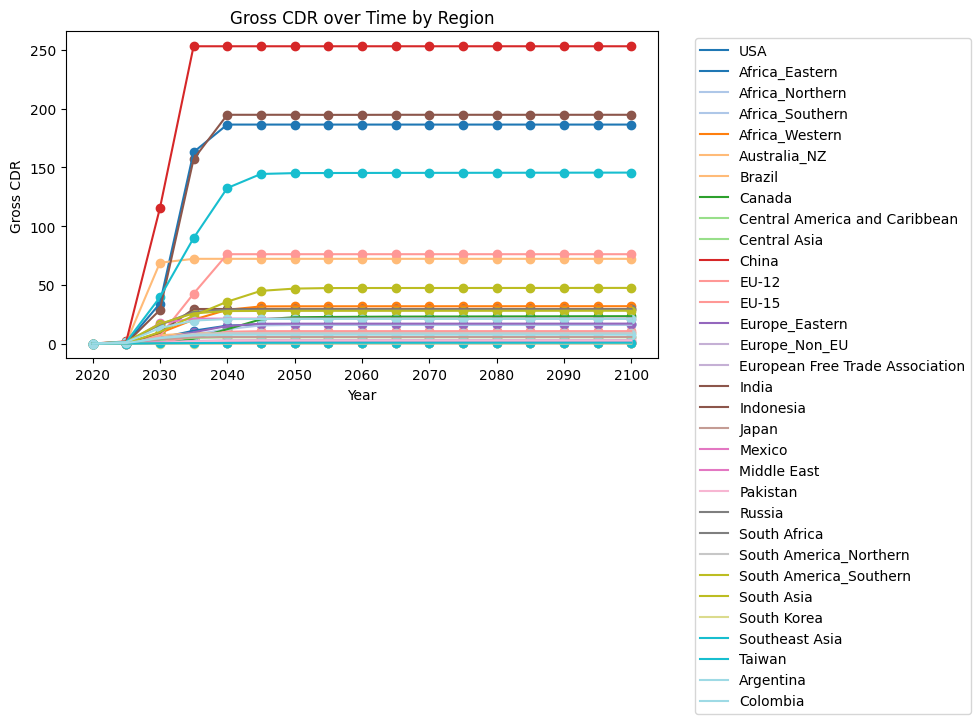

In [27]:
import matplotlib.cm as cm

regions = dfm["region"].unique()
num_regions = len(regions)

# Choose a colormap (e.g., 'tab20', 'tab20c', 'viridis', 'nipy_spectral')
cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more

plt.figure(figsize=(10,6))

for i, region in enumerate(regions):
    group = dfm[dfm["region"] == region]
    plt.plot(group["year"], group["gross_CDR_MTC"], 
             color=cmap(i), label=region)
    plt.scatter(group["year"], group["gross_CDR_MTC"], 
             color=cmap(i))

plt.xlabel("Year")
plt.ylabel("Gross CDR")
plt.title("Gross CDR over Time by Region")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # legend outside plot
plt.tight_layout()
# plt.ylim(0,1)
plt.show()

### Interpolate time grid

In [28]:
# set the yearly grid
years = np.arange(dfm['year'].astype(int).min(), dfm['year'].astype(int).max() + 1, 1)

# --- interpolate each region separately
dfs_interpolated = []

for region, group in dfm.groupby("region"):
    # sort by time just in case
    group = group.sort_values("year")
    
    # interpolate gross CDR to yearly time
    interp_values = np.interp(years, group["year"], group["gross_CDR_MTC"])
    
    # Make new dataframe
    df_interp = pd.DataFrame({
        "region": region,
        "year": years,
        "gross_CDR_MTC": interp_values
    })

    # repeat the other columns (taking the first value in the group)
    for col in ['scenario', 'sector', 'technology', 'subsector', 'Units']:
        df_interp[col] = group[col].iloc[0]
    
    dfs_interpolated.append(df_interp)

# Combine all regions
df_yearly = pd.concat(dfs_interpolated, ignore_index=True)


### Plot -- check that interpolation worked

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_74615/2246590686.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more


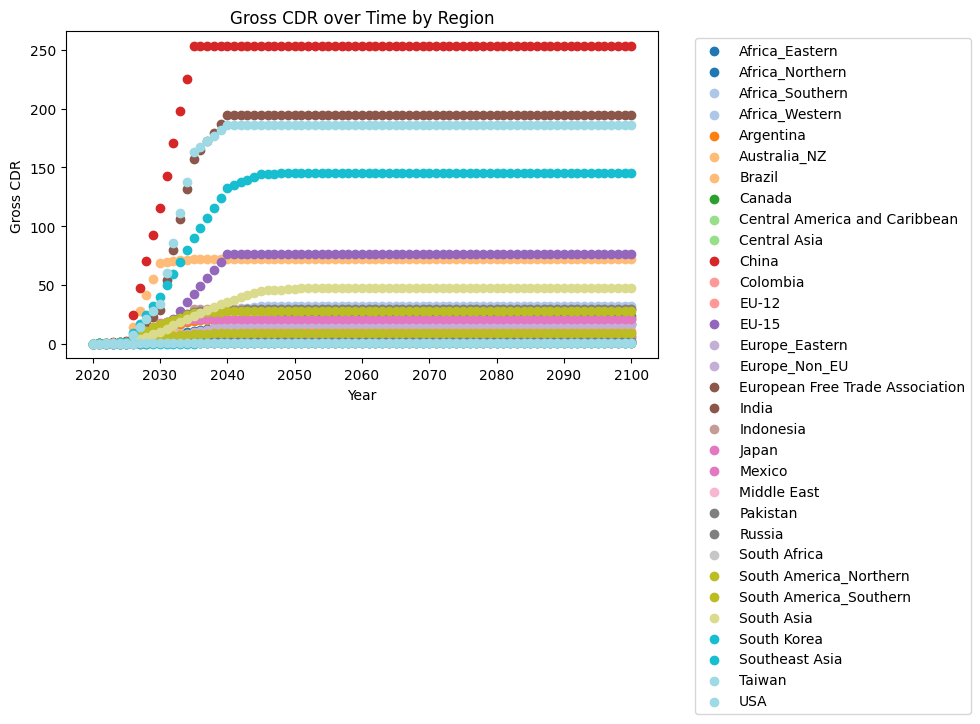

In [29]:
regions = df_yearly["region"].unique()
num_regions = len(regions)

# Choose a colormap (e.g., 'tab20', 'tab20c', 'viridis', 'nipy_spectral')
cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more

plt.figure(figsize=(10,6))

for i, region in enumerate(regions):
    group = df_yearly[df_yearly["region"] == region]
    plt.scatter(group["year"], group["gross_CDR_MTC"], 
             color=cmap(i), label=region)

plt.xlabel("Year")
plt.ylabel("Gross CDR")
plt.title("Gross CDR over Time by Region")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # legend outside plot
plt.tight_layout()
# plt.ylim(0,1)
plt.show()

### Convert CDR to rock application amounts

In [30]:
# conversion factors
C_to_CO2 = 44 / 12    # [g CO2 / g C]
basalt_cdrpot = 0.3   # [g CO2 / g basalt]
MT_to_t = 1e6  # [Mt per ton]
# calculate yearly rock application in tonnes
df_yearly['rockflx_Mt_yr'] = df_yearly['gross_CDR_MTC'] * C_to_CO2 * (1/basalt_cdrpot)
df_yearly['rockflx_t_yr'] = df_yearly['rockflx_Mt_yr'] * MT_to_t
# calculate gcam-derived CDR in MT CO2 
df_yearly['gcam_gross_cdr_mtCO2'] = df_yearly['gross_CDR_MTC'] * C_to_CO2

### Plot result

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_74615/1106366770.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more


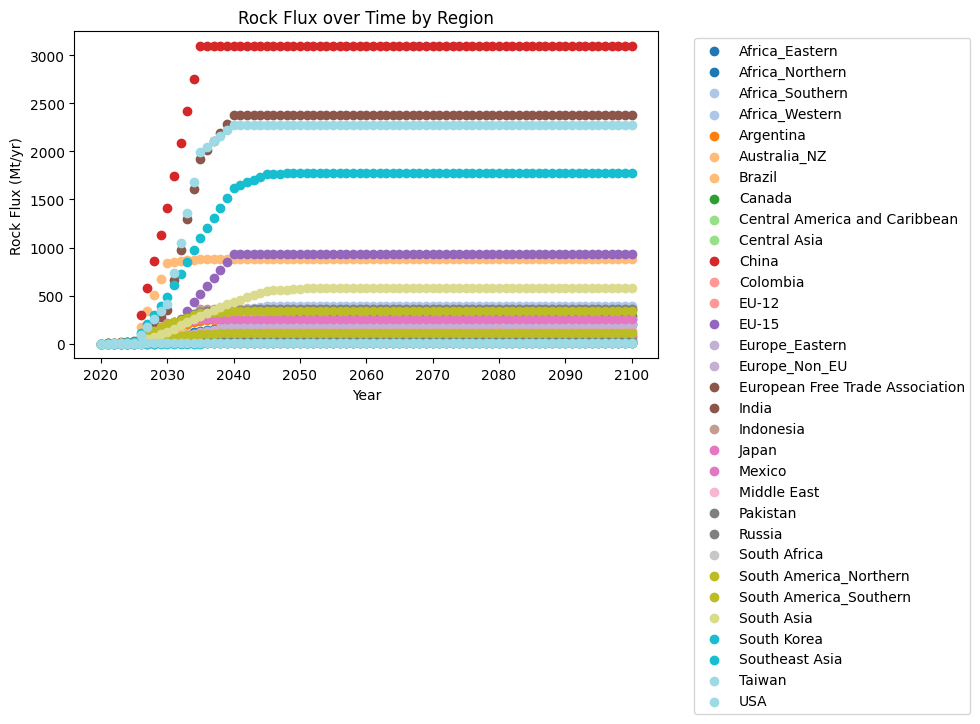

In [31]:
regions = df_yearly["region"].unique()
num_regions = len(regions)

# Choose a colormap (e.g., 'tab20', 'tab20c', 'viridis', 'nipy_spectral')
cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more

plt.figure(figsize=(10,6))

for i, region in enumerate(regions):
    group = df_yearly[df_yearly["region"] == region]
    plt.scatter(group["year"], group["rockflx_Mt_yr"], 
             color=cmap(i), label=region)

plt.xlabel("Year")
plt.ylabel("Rock Flux (Mt/yr)")
plt.title("Rock Flux over Time by Region")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # legend outside plot
plt.tight_layout()
# plt.ylim(0,1)
plt.show()

## Map on gcam boundaries to df

In [32]:
# --- first add a 'reg_id' column to the yearly data
import geopandas as gpd
# [ read in gdf ]
datdir = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/gcam_boundaries_moirai_3p1_0p5arcmin_wgs84/main_outputs/'
fn = "region_boundaries_moirai_landcells_3p1_0p5arcmin.shp"
gdf = gpd.read_file(os.path.join(datdir, fn))

# map region names to id
dfx = df_yearly.merge(
    gdf[["reg_nm", "reg_id"]],
    left_on="region",
    right_on="reg_nm",
    how="left"
)
# drop duplicate col
dfx = dfx.drop(columns=["reg_nm"])

# SCENARIO 1: Rock fluxes over time for each pixel, constant area

## For each region, get the ton/ha time series for the pixel with the most rock at year 80
This pixel is the one in the region with the highest cropland fraction. We'll use this pixel as our stand-in for each region. This lets us run one simulation per region, then we can get regional amount of CDR by multiplying ton/ha/yr by regional area. 

## Loop through crop area fractions

In [10]:
# --- set the fraction of cropland used (applies to all regions) --
crop_area_frac_arr = np.round(np.linspace(0.1, 1, 10), 2) # from 10% to 100% in 10% increments
# -----------------------------------------------------------------
# 

for crop_area_frac in crop_area_frac_arr:
    # copy ds so we don't overwrite
    ds_rock = ds.copy()

    # --- ensure df is sorted by time, reg_id
    dfx = dfx.sort_values(["year", "reg_id"])

    # --- create a pivot table for easy indexing
    # rows = time, columns = reg_id, values = rockflx_Mt_yr
    rock_pivot = dfx.pivot(index="year", columns="reg_id", values="rockflx_Mt_yr")
    rock_pivot_gcam_cdr = dfx.pivot(index="year", columns="reg_id", values="gross_CDR_MTC")
    # --- get arrays for dimensions
    times = rock_pivot.index.values
    reg_ids = rock_pivot.columns.values

    # --- create a 3D DataArray for the rock flux in each pixel
    # expand frac_regional_cropland to have a time dimension
    frac = ds_rock["frac_regional_cropland"]
    # stack x/y to simplify indexing
    frac_stacked = frac.stack(z=("y", "x"))
    frac_vals = np.where(np.isfinite(frac_stacked.values), frac_stacked.values, 0.0) # sanitize frac values to avoid NaN issues in multiplication

    # stack x/y to simplify indexing
    frac_stacked = frac.stack(z=("y", "x"))
    # get region ids as an array
    reg_id_arr = ds_rock["reg_id"].stack(z=("y", "x"))

    # initialize array to hold rock flux
    rock_flux_data = np.zeros((len(times), frac_stacked.z.size), dtype=float)

    # --- loop over times (vectorizing over pixels using broadcasting)
    for i, t in enumerate(times):
        # rock flux per region for this time
        flux_by_region = rock_pivot.loc[t].to_dict()  # {reg_id: rockflx_Mt_yr}
        # gcam cdr flux per region for this time 
        gcam_cdr_by_region = rock_pivot_gcam_cdr.loc[t].to_dict()
        # map each pixel's reg_id to flux_by_region
        rock_flux_data[i, :] = np.array([flux_by_region.get(rid, 0) for rid in reg_id_arr.values]) * frac_vals

    # reshape back to (time, y, x)
    rock_flux_da = xr.DataArray(
        rock_flux_data.reshape((len(times), frac.shape[0], frac.shape[1])),
        coords={"time": times, "y": ds_rock.y, "x": ds_rock.x},
        dims=("time", "y", "x"),
        name="rockflx_Mt"
    )

    # --- add to dataset
    ds_rock["rockflx_Mt"] = rock_flux_da

    # --- compute flux per hectare
    # cropland_area in m2 → ha = m2 / 10000
    cropland_ha = ds_rock["cropland_area"] / 1e4
    ds_rock["rockflx_Mt_ha"] = ds_rock["rockflx_Mt"] / (crop_area_frac * cropland_ha.where(cropland_ha > 0))
    # --- compute flux in t/ha
    ds_rock['rockflx_t_ha'] = ds_rock["rockflx_Mt_ha"] * 1e6

    # ---------------------------------------------------------------------------------------

    # ----------------------------------------
    # 1) find global max pixel per reg_id
    # ----------------------------------------

    # take max over time first
    rock_max_time = ds_rock["rockflx_Mt"].max(dim="time")

    # flatten to dataframe
    flat_max = pd.DataFrame({
        "y": rock_max_time.y.values.repeat(rock_max_time.x.size),
        "x": np.tile(rock_max_time.x.values, rock_max_time.y.size),
        "reg_id": ds_rock["reg_id"].values.flatten(),
        "rockflx_Mt_max": rock_max_time.values.flatten(),
    })

    # remove background pixels
    flat_max = flat_max[flat_max["reg_id"] > 0]

    # get index of maximum pixel per region
    idx_max = flat_max.groupby("reg_id")["rockflx_Mt_max"].idxmax()

    # fixed pixel per region
    df_fixed_pixels = flat_max.loc[idx_max, ["reg_id", "y", "x"]].copy()
    df_fixed_pixels.rename(columns={"y": "lat", "x": "lon"}, inplace=True)
    df_fixed_pixels = df_fixed_pixels.sort_values("reg_id").reset_index(drop=True)

    # ----------------------------------------
    # 2) vectorized pairwise indexing
    # ----------------------------------------

    # build pairwise indexers (shared dimension name!)
    fixed_lats = xr.DataArray(
        df_fixed_pixels["lat"].values,
        dims="reg"
    )

    fixed_lons = xr.DataArray(
        df_fixed_pixels["lon"].values,
        dims="reg"
    )

    # select time series at those exact pixel pairs
    ds_selected = ds_rock.sel(
        y=fixed_lats,
        x=fixed_lons
    )

    # attach reg_id as coordinate
    ds_selected = ds_selected.assign_coords(
        reg_id=("reg", df_fixed_pixels["reg_id"].values)
    )

    # ----------------------------------------
    # 3) convert to pandas
    # ----------------------------------------

    df_max_all_years = (
        ds_selected[["rockflx_Mt", "rockflx_Mt_ha", "rockflx_t_ha"]]
        .to_dataframe()
        .reset_index()
    )

    # rename spatial columns
    df_max_all_years = df_max_all_years.rename(
        columns={"y": "lat", "x": "lon"}
    )

    # ----------------------------------------
    # 4) add region names and clean
    # ----------------------------------------

    regid_to_name = dict(zip(gdf["reg_id"], gdf["reg_nm"]))

    df_max_all_years["region"] = (
        df_max_all_years["reg_id"].map(regid_to_name)
    )

    df_max_all_years[["rockflx_t_ha", "rockflx_Mt_ha"]] = (
        df_max_all_years[["rockflx_t_ha", "rockflx_Mt_ha"]]
        .fillna(0)
    )

    df_max_all_years = df_max_all_years[
        ["reg_id", "region", "time",
        "rockflx_t_ha", "rockflx_Mt_ha", "rockflx_Mt",
        "lat", "lon"]
    ].sort_values(["reg_id", "time"]).reset_index(drop=True)

    # --- add gcam-derived gross CDR 
    dfx['time'] = dfx['year']
    dfout = df_max_all_years.merge(
        dfx[["region", "time", "gcam_gross_cdr_mtCO2"]],
        on=["region", "time"],
        how="left"   # keeps all rows from df_main
    )

    # --- [ SAVE RESULTS ]
    # --- update region names to exclude spaces 
    dfout["region_nospaces"] = dfout["region"].str.replace(" ", "_", regex=False)

    savehere = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/'
    subdir = f'one-cell-per-region/{RUNNAME}/{crop_area_frac}-cropFraction'
    fn_df = f'annual_rockflx_densest-ag-region_{deg_resolution}deg.pkl'
    fn_ds = f'cropland+gcamRegions_time_{deg_resolution}deg.zarr'

    # save df
    dfout.to_pickle(os.path.join(savehere, subdir, fn_df))
    ds_rock.to_zarr(os.path.join(savehere, subdir, fn_ds))

FileExistsError: Cannot create '' with mode 'w-' because it already contains data. Use mode 'w' to overwrite or 'a' to append.

## quick plot

In [ ]:
ds_rock.isel(time=80)['rockflx_Mt'].plot()
# ds_rock.isel(time=80)['rockflx_t_ha'].plot()
# ds_rock.where(ds_rock['cropland_area'] > 1).isel(time=80)['cropland_area'].plot()
# ds_rock.isel(time=80)['cropland_area'].plot()

# SCENARIO 2: Rock fluxes over time for each region, constant application rate until cropland saturation

## Loop through application rates
Assume a fixed application rate (t/ha/yr) and compute the cropland area and fraction required to spread
the GCAM-prescribed total rock for each region and year. If the required cropland fraction exceeds 1,
use all cropland and increase the application rate to preserve the total rock amount.

In [41]:
# --- user-defined application rates (tonnes/ha/yr)
app_rate_arr = np.array([5, 7.5, 10, 15, 20, 30, 40, 50])   # edit as needed

# pre-compute total cropland ha per region (time-invariant)
cropland_ha_flat = (ds["cropland_area"].values / 1e4).flatten()
reg_id_flat = ds["reg_id"].values.flatten()
total_cropland_ha_by_reg = {
    int(rid): np.nansum(cropland_ha_flat[reg_id_flat == rid])
    for rid in np.unique(reg_id_flat[reg_id_flat > 0])
}

for app_rate in app_rate_arr:
    ds_rock = ds.copy()
    df_s2 = dfx.sort_values(["year", "reg_id"]).copy()

    # --- regional area and fraction calculations
    df_s2["total_cropland_ha"] = df_s2["reg_id"].map(total_cropland_ha_by_reg)
    df_s2["cropland_area_required_ha"] = df_s2["rockflx_t_yr"] / app_rate
    df_s2["cropland_fraction_required"] = (
        df_s2["cropland_area_required_ha"] / df_s2["total_cropland_ha"]
    )
    df_s2["cropland_fraction_effective"] = df_s2["cropland_fraction_required"].clip(upper=1.0)
    # if fraction > 1: boost rate so total rock = effective_rate * total_cropland_ha
    df_s2["effective_rate_t_ha"] = np.where(
        df_s2["cropland_fraction_required"] > 1,
        df_s2["rockflx_t_yr"] / df_s2["total_cropland_ha"],
        app_rate
    )
    df_s2["effective_rate_t_ha"] = df_s2["effective_rate_t_ha"].fillna(0)

    # --- pivot tables for spatial mapping
    rate_pivot = df_s2.pivot(index="year", columns="reg_id", values="effective_rate_t_ha")
    rock_pivot_gcam_cdr = df_s2.pivot(index="year", columns="reg_id", values="gross_CDR_MTC")
    times = rate_pivot.index.values

    # --- map effective rate and rock flux to pixels
    reg_id_arr = ds_rock["reg_id"].stack(z=("y", "x"))
    cropland_ha_stacked = (ds_rock["cropland_area"] / 1e4).stack(z=("y", "x"))
    cropland_ha_vals = np.where(
        np.isfinite(cropland_ha_stacked.values), cropland_ha_stacked.values, 0.0
    )

    rate_data = np.zeros((len(times), reg_id_arr.size), dtype=float)
    rock_flux_data = np.zeros((len(times), reg_id_arr.size), dtype=float)

    for i, t in enumerate(times):
        rate_by_region = rate_pivot.loc[t].to_dict()
        rate_data[i, :] = np.array([rate_by_region.get(rid, 0) for rid in reg_id_arr.values])
        rock_flux_data[i, :] = rate_data[i, :] * cropland_ha_vals / 1e6  # t/ha * ha / 1e6 → Mt

    ny, nx = ds_rock["cropland_area"].shape
    rate_da = xr.DataArray(
        rate_data.reshape((len(times), ny, nx)),
        coords={"time": times, "y": ds_rock.y, "x": ds_rock.x},
        dims=("time", "y", "x"),
        name="rockflx_t_ha"
    )
    rock_flux_da = xr.DataArray(
        rock_flux_data.reshape((len(times), ny, nx)),
        coords={"time": times, "y": ds_rock.y, "x": ds_rock.x},
        dims=("time", "y", "x"),
        name="rockflx_Mt"
    )
    ds_rock["rockflx_t_ha"] = rate_da
    ds_rock["rockflx_Mt_ha"] = rate_da / 1e6
    ds_rock["rockflx_Mt"] = rock_flux_da

    # ----------------------------------------
    # 1) find representative pixel per region
    #    (highest cropland ha = highest rockflx_Mt, since rate is uniform within region)
    # ----------------------------------------
    rock_max_time = ds_rock["rockflx_Mt"].max(dim="time")
    flat_max = pd.DataFrame({
        "y": rock_max_time.y.values.repeat(rock_max_time.x.size),
        "x": np.tile(rock_max_time.x.values, rock_max_time.y.size),
        "reg_id": ds_rock["reg_id"].values.flatten(),
        "rockflx_Mt_max": rock_max_time.values.flatten(),
    })
    flat_max = flat_max[flat_max["reg_id"] > 0]
    idx_max = flat_max.groupby("reg_id")["rockflx_Mt_max"].idxmax()
    df_fixed_pixels = flat_max.loc[idx_max, ["reg_id", "y", "x"]].copy()
    df_fixed_pixels.rename(columns={"y": "lat", "x": "lon"}, inplace=True)
    df_fixed_pixels = df_fixed_pixels.sort_values("reg_id").reset_index(drop=True)

    # ----------------------------------------
    # 2) extract time series at representative pixels
    # ----------------------------------------
    fixed_lats = xr.DataArray(df_fixed_pixels["lat"].values, dims="reg")
    fixed_lons = xr.DataArray(df_fixed_pixels["lon"].values, dims="reg")
    ds_selected = ds_rock.sel(y=fixed_lats, x=fixed_lons)
    ds_selected = ds_selected.assign_coords(
        reg_id=("reg", df_fixed_pixels["reg_id"].values)
    )

    df_max_all_years = (
        ds_selected[["rockflx_Mt", "rockflx_Mt_ha", "rockflx_t_ha"]]
        .to_dataframe()
        .reset_index()
    )
    df_max_all_years = df_max_all_years.rename(columns={"y": "lat", "x": "lon"})

    # ----------------------------------------
    # 3) add region names and Scenario 2 diagnostics
    # ----------------------------------------
    regid_to_name = dict(zip(gdf["reg_id"], gdf["reg_nm"]))
    df_max_all_years["region"] = df_max_all_years["reg_id"].map(regid_to_name)
    df_max_all_years[["rockflx_t_ha", "rockflx_Mt_ha"]] = (
        df_max_all_years[["rockflx_t_ha", "rockflx_Mt_ha"]].fillna(0)
    )
    df_max_all_years = df_max_all_years[
        ["reg_id", "region", "time",
         "rockflx_t_ha", "rockflx_Mt_ha", "rockflx_Mt",
         "lat", "lon"]
    ].sort_values(["reg_id", "time"]).reset_index(drop=True)

    df_s2["time"] = df_s2["year"]
    dfout = df_max_all_years.merge(
        df_s2[["region", "time", "gcam_gross_cdr_mtCO2",
               "cropland_area_required_ha", "cropland_fraction_required",
               "cropland_fraction_effective", "effective_rate_t_ha"]],
        on=["region", "time"],
        how="left"
    )

    # --- [ SAVE RESULTS ]
    dfout["region_nospaces"] = dfout["region"].str.replace(" ", "_", regex=False)
    savehere = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/'
    subdir = f'one-cell-per-region/{RUNNAME}/{app_rate}-tHaYr-appRate'
    fn_df = f'annual_rockflx_densest-ag-region_{deg_resolution}deg.pkl'
    fn_ds = f'cropland+gcamRegions_time_{deg_resolution}deg.zarr'

    dfout.to_pickle(os.path.join(savehere, subdir, fn_df))
    ds_rock.to_zarr(os.path.join(savehere, subdir, fn_ds))

/Users/tylerkukla/Documents/GitHub/iam-rtm-compare/.venv/lib/python3.13/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/Users/tylerkukla/Documents/GitHub/iam-rtm-compare/.venv/lib/python3.13/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/Users/tylerkukla/Documents/GitHub/iam-rtm-compare/.venv/lib/python3.13/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/Users/tylerkukla/Documents/GitHub/iam-rtm-compare/.venv/l

## quickplot

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_22780/3159574733.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more


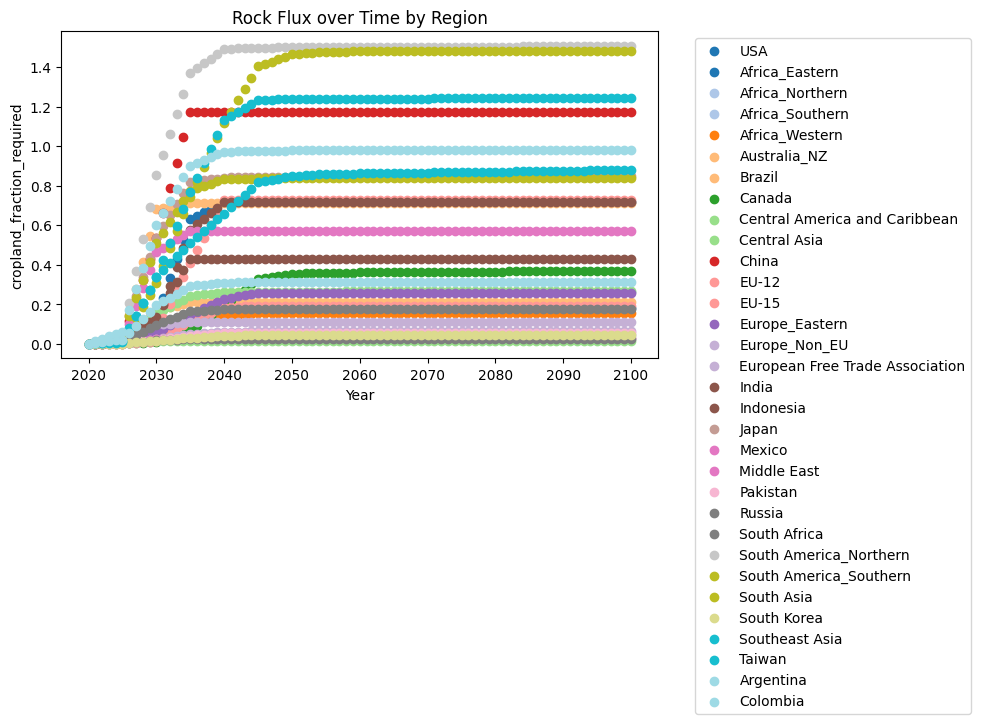

In [42]:
# --- read in data
# pick apprate
apprate_test = 20.0
subdir = f'one-cell-per-region/{RUNNAME}/{apprate_test}-tHaYr-appRate'
dftest = pd.read_pickle(os.path.join(savehere, subdir, fn_df))

# --- by crop area
# 
regions = dftest["region"].unique()
num_regions = len(regions)
pvar = "cropland_fraction_required"
# Choose a colormap (e.g., 'tab20', 'tab20c', 'viridis', 'nipy_spectral')
cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more

plt.figure(figsize=(10,6))

for i, region in enumerate(regions):
    group = dftest[dftest["region"] == region]
    plt.scatter(group["time"], group[pvar], 
             color=cmap(i), label=region)

plt.xlabel("Year")
plt.ylabel(pvar)
plt.title("Rock Flux over Time by Region")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # legend outside plot
plt.tight_layout()
# plt.ylim(0,1)
plt.show()

In [18]:
dfout

,reg_id,region,time,rockflx_t_ha,rockflx_Mt_ha,rockflx_Mt,lat,lon,gcam_gross_cdr_mtCO2,cropland_area_required_ha,cropland_fraction_required,cropland_fraction_effective,effective_rate_t_ha
0,1,USA,2020,50.0,0.00005,40.625302,40.5,-97.5,0.000000,0.000000e+00,0.000000,0.000000,50.0
1,1,USA,2021,50.0,0.00005,40.625302,40.5,-97.5,0.188416,1.256107e+04,0.000079,0.000079,50.0
2,1,USA,2022,50.0,0.00005,40.625302,40.5,-97.5,0.376832,2.512214e+04,0.000159,0.000159,50.0
3,1,USA,2023,50.0,0.00005,40.625302,40.5,-97.5,0.565248,3.768321e+04,0.000238,0.000238,50.0
4,1,USA,2024,50.0,0.00005,40.625302,40.5,-97.5,0.753664,5.024428e+04,0.000317,0.000317,50.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2587,32,Colombia,2096,50.0,0.00005,7.106142,3.5,-76.5,27.597455,1.839830e+06,0.390020,0.390020,50.0
2588,32,Colombia,2097,50.0,0.00005,7.106142,3.5,-76.5,27.597974,1.839865e+06,0.390027,0.390027,50.0
2589,32,Colombia,2098,50.0,0.00005,7.106142,3.5,-76.5,27.598494,1.839900e+06,0.390035,0.390035,50.0
2590,32,Colombia,2099,50.0,0.00005,7.106142,3.5,-76.5,27.599014,1.839934e+06,0.390042,0.390042,50.0


# SCENARIO 3: Constant application rate, and don't change it if we saturate the cropland area
(Scenario 2 updates the application rate to more rock if we saturate the crop area -- we avoid that here just to keep the apprate constant). 

In [33]:
# --- user-defined application rates (tonnes/ha/yr)
app_rate_arr = np.array([0.25, 0.75]) # np.array([0.05, 0.1, 0.5, 1., 2.5])  # np.array([5, 7.5, 10, 15, 20, 30, 40, 50])   # edit as needed

# pre-compute total cropland ha per region (time-invariant)
cropland_ha_flat = (ds["cropland_area"].values / 1e4).flatten()
reg_id_flat = ds["reg_id"].values.flatten()
total_cropland_ha_by_reg = {
    int(rid): np.nansum(cropland_ha_flat[reg_id_flat == rid])
    for rid in np.unique(reg_id_flat[reg_id_flat > 0])
}

for app_rate in app_rate_arr:
    ds_rock = ds.copy()
    df_s3 = dfx.sort_values(["year", "reg_id"]).copy()

    # --- regional area and fraction calculations (diagnostic only — rate never changes)
    df_s3["total_cropland_ha"] = df_s3["reg_id"].map(total_cropland_ha_by_reg)
    df_s3["cropland_area_required_ha"] = df_s3["rockflx_t_yr"] / app_rate
    df_s3["cropland_fraction_required"] = (
        df_s3["cropland_area_required_ha"] / df_s3["total_cropland_ha"]
    )
    # rate is fixed so effective == required (no saturation cap applied)
    df_s3["cropland_fraction_effective"] = df_s3["cropland_fraction_required"]
    df_s3["effective_rate_t_ha"] = app_rate

    # --- pivot tables for spatial mapping
    rate_pivot = df_s3.pivot(index="year", columns="reg_id", values="effective_rate_t_ha")
    rock_pivot_gcam_cdr = df_s3.pivot(index="year", columns="reg_id", values="gross_CDR_MTC")
    times = rate_pivot.index.values

    # --- map effective rate and rock flux to pixels
    reg_id_arr = ds_rock["reg_id"].stack(z=("y", "x"))
    cropland_ha_stacked = (ds_rock["cropland_area"] / 1e4).stack(z=("y", "x"))
    cropland_ha_vals = np.where(
        np.isfinite(cropland_ha_stacked.values), cropland_ha_stacked.values, 0.0
    )

    rate_data = np.zeros((len(times), reg_id_arr.size), dtype=float)
    rock_flux_data = np.zeros((len(times), reg_id_arr.size), dtype=float)

    for i, t in enumerate(times):
        rate_by_region = rate_pivot.loc[t].to_dict()
        rate_data[i, :] = np.array([rate_by_region.get(rid, 0) for rid in reg_id_arr.values])
        rock_flux_data[i, :] = rate_data[i, :] * cropland_ha_vals / 1e6  # t/ha * ha / 1e6 → Mt

    ny, nx = ds_rock["cropland_area"].shape
    rate_da = xr.DataArray(
        rate_data.reshape((len(times), ny, nx)),
        coords={"time": times, "y": ds_rock.y, "x": ds_rock.x},
        dims=("time", "y", "x"),
        name="rockflx_t_ha"
    )
    rock_flux_da = xr.DataArray(
        rock_flux_data.reshape((len(times), ny, nx)),
        coords={"time": times, "y": ds_rock.y, "x": ds_rock.x},
        dims=("time", "y", "x"),
        name="rockflx_Mt"
    )
    ds_rock["rockflx_t_ha"] = rate_da
    ds_rock["rockflx_Mt_ha"] = rate_da / 1e6
    ds_rock["rockflx_Mt"] = rock_flux_da

    # ----------------------------------------
    # 1) find representative pixel per region
    # ----------------------------------------
    rock_max_time = ds_rock["rockflx_Mt"].max(dim="time")
    flat_max = pd.DataFrame({
        "y": rock_max_time.y.values.repeat(rock_max_time.x.size),
        "x": np.tile(rock_max_time.x.values, rock_max_time.y.size),
        "reg_id": ds_rock["reg_id"].values.flatten(),
        "rockflx_Mt_max": rock_max_time.values.flatten(),
    })
    flat_max = flat_max[flat_max["reg_id"] > 0]
    idx_max = flat_max.groupby("reg_id")["rockflx_Mt_max"].idxmax()
    df_fixed_pixels = flat_max.loc[idx_max, ["reg_id", "y", "x"]].copy()
    df_fixed_pixels.rename(columns={"y": "lat", "x": "lon"}, inplace=True)
    df_fixed_pixels = df_fixed_pixels.sort_values("reg_id").reset_index(drop=True)

    # ----------------------------------------
    # 2) extract time series at representative pixels
    # ----------------------------------------
    fixed_lats = xr.DataArray(df_fixed_pixels["lat"].values, dims="reg")
    fixed_lons = xr.DataArray(df_fixed_pixels["lon"].values, dims="reg")
    ds_selected = ds_rock.sel(y=fixed_lats, x=fixed_lons)
    ds_selected = ds_selected.assign_coords(
        reg_id=("reg", df_fixed_pixels["reg_id"].values)
    )

    df_max_all_years = (
        ds_selected[["rockflx_Mt", "rockflx_Mt_ha", "rockflx_t_ha"]]
        .to_dataframe()
        .reset_index()
    )
    df_max_all_years = df_max_all_years.rename(columns={"y": "lat", "x": "lon"})

    # ----------------------------------------
    # 3) add region names and Scenario 3 diagnostics
    # ----------------------------------------
    regid_to_name = dict(zip(gdf["reg_id"], gdf["reg_nm"]))
    df_max_all_years["region"] = df_max_all_years["reg_id"].map(regid_to_name)
    df_max_all_years[["rockflx_t_ha", "rockflx_Mt_ha"]] = (
        df_max_all_years[["rockflx_t_ha", "rockflx_Mt_ha"]].fillna(0)
    )
    df_max_all_years = df_max_all_years[
        ["reg_id", "region", "time",
         "rockflx_t_ha", "rockflx_Mt_ha", "rockflx_Mt",
         "lat", "lon"]
    ].sort_values(["reg_id", "time"]).reset_index(drop=True)

    df_s3["time"] = df_s3["year"]
    dfout = df_max_all_years.merge(
        df_s3[["region", "time", "gcam_gross_cdr_mtCO2",
               "cropland_area_required_ha", "cropland_fraction_required",
               "cropland_fraction_effective", "effective_rate_t_ha"]],
        on=["region", "time"],
        how="left"
    )

    # # --- [ SAVE RESULTS ]
    dfout["region_nospaces"] = dfout["region"].str.replace(" ", "_", regex=False)
    savehere = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/'
    subdir = f'one-cell-per-region/{RUNNAME}/{app_rate}-tHaYr-appRate-FIXED'
    fn_df = f'annual_rockflx_densest-ag-region_{deg_resolution}deg.pkl'
    fn_ds = f'cropland+gcamRegions_time_{deg_resolution}deg.zarr'

    dfout.to_pickle(os.path.join(savehere, subdir, fn_df))
    ds_rock.to_zarr(os.path.join(savehere, subdir, fn_ds))

/Users/tylerkukla/Documents/GitHub/iam-rtm-compare/.venv/lib/python3.13/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/Users/tylerkukla/Documents/GitHub/iam-rtm-compare/.venv/lib/python3.13/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_74615/756625123.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more


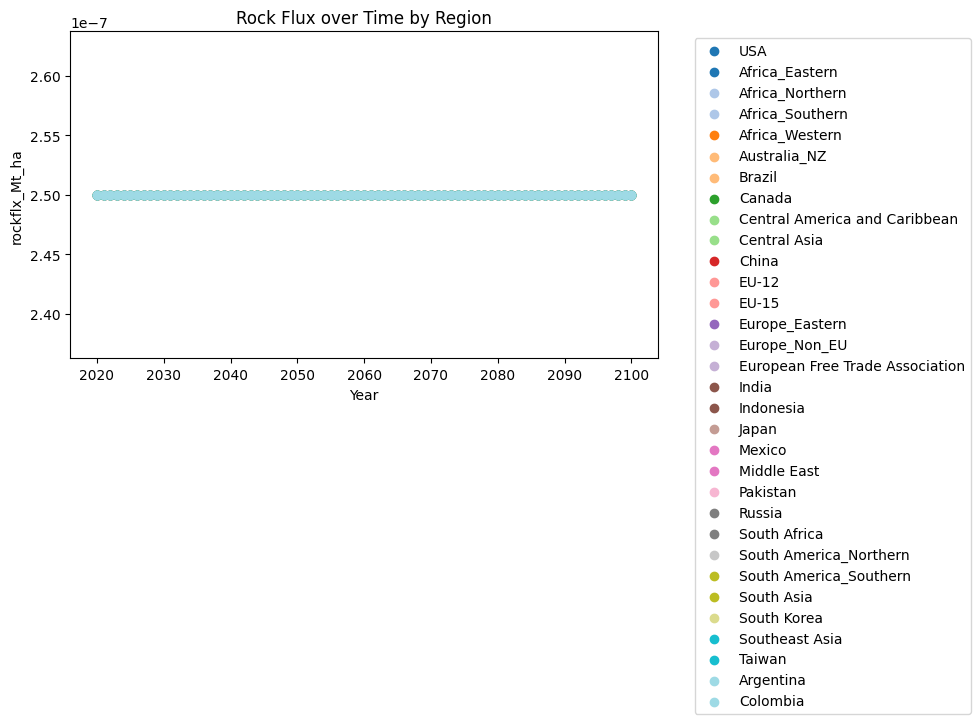

In [34]:
# --- read in data
# pick apprate
apprate_test = 0.25
subdir = f'one-cell-per-region/{RUNNAME}/{apprate_test}-tHaYr-appRate-FIXED'
dftest = pd.read_pickle(os.path.join(savehere, subdir, fn_df))

# --- by crop area
# 
regions = dftest["region"].unique()
num_regions = len(regions)
# pvar = "cropland_fraction_required"
pvar = "rockflx_Mt_ha"
# Choose a colormap (e.g., 'tab20', 'tab20c', 'viridis', 'nipy_spectral')
cmap = cm.get_cmap('tab20', num_regions)  # 'tab20' can handle up to 20 colors, 'nipy_spectral' for more

plt.figure(figsize=(10,6))

for i, region in enumerate(regions):
    group = dftest[dftest["region"] == region]
    plt.scatter(group["time"], group[pvar], 
             color=cmap(i), label=region)

plt.xlabel("Year")
plt.ylabel(pvar)
plt.title("Rock Flux over Time by Region")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # legend outside plot
plt.tight_layout()
# plt.ylim(0,1)
plt.show()

In [ ]:
# ---